# Graphical Models on the Student Success Dataset

Lecture 14 emphasized three ideas:

1. Naive Bayes is a Bayesian network with a star-shaped graph.
2. Real data often violate the conditional-independence assumptions of Naive Bayes.
3. Once we fix a graph, parameter learning is just counting entries in conditional probability tables (CPTs).

This notebook uses the local `student_academic_success.csv` dataset that is already in this folder, so the example stays self-contained. To keep the classifier focused, we restrict attention to the two clearly labeled outcomes `Graduate` and `Dropout`, then engineer a small collection of discrete variables.

In [1]:
import itertools
import math
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import chi2_contingency
from sklearn.metrics import accuracy_score, log_loss
from sklearn.model_selection import train_test_split

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 120
pd.set_option("display.max_colwidth", None)

RANDOM_STATE = 42

In [2]:
data_path = Path("student_academic_success.csv")
if not data_path.exists():
    data_path = Path("notebooks") / "student_academic_success.csv"

raw_df = pd.read_csv(data_path, sep=";")
df = raw_df[raw_df["Target"].isin(["Graduate", "Dropout"])].copy()

df["Age band"] = pd.cut(
    df["Age at enrollment"],
    bins=[0, 20, 25, np.inf],
    labels=["18-20", "21-25", "26+"],
    include_lowest=True,
)
df["Admission band"] = pd.cut(
    df["Admission grade"],
    bins=[0, 120, 140, np.inf],
    labels=["Low", "Mid", "High"],
    include_lowest=True,
    right=False,
)
df["Scholarship"] = df["Scholarship holder"].map({1: "Yes", 0: "No"})
df["Tuition current"] = df["Tuition fees up to date"].map({1: "Yes", 0: "No"})
df["Debtor"] = df["Debtor"].map({1: "Yes", 0: "No"})
df["Semester 1 progress"] = np.where(
    df["Curricular units 1st sem (approved)"] >= 5,
    "Strong",
    "Weak",
)
df["Semester 2 progress"] = np.where(
    df["Curricular units 2nd sem (approved)"] >= 5,
    "Strong",
    "Weak",
)

model_columns = [
    "Target",
    "Age band",
    "Admission band",
    "Scholarship",
    "Tuition current",
    "Debtor",
    "Semester 1 progress",
    "Semester 2 progress",
]
model_df = df[model_columns].copy()
for column in model_df.columns:
    model_df[column] = model_df[column].astype(str)

train_df, holdout_df = train_test_split(
    model_df,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=model_df["Target"],
)

print(f"Rows kept after removing the 'Enrolled' class: {len(model_df)}")
display(model_df.head())

class_summary = pd.DataFrame(
    {
        "Count": model_df["Target"].value_counts(),
        "Proportion": model_df["Target"].value_counts(normalize=True).round(3),
    }
)
display(class_summary)

Rows kept after removing the 'Enrolled' class: 3630


,Target,Age band,Admission band,Scholarship,Tuition current,Debtor,Semester 1 progress,Semester 2 progress
0,Dropout,18-20,Mid,No,Yes,No,Weak,Weak
1,Graduate,18-20,High,No,No,No,Strong,Strong
2,Dropout,18-20,Mid,No,No,No,Weak,Weak
3,Graduate,18-20,Low,No,Yes,No,Strong,Strong
4,Graduate,26+,High,No,Yes,No,Strong,Strong


,Count,Proportion
Target,,
Graduate,2209,0.609
Dropout,1421,0.391


## Two Bayesian-Network Classifiers

We will compare two models built from the same variables. The arrows below encode a probabilistic factorization, not a causal claim.

- **Naive Bayes:** every feature is conditionally independent given `Target`.
- **Richer BN:** we keep two extra dependencies that the data strongly suggest:
  - `Tuition current -> Debtor`
  - `Semester 1 progress -> Semester 2 progress`

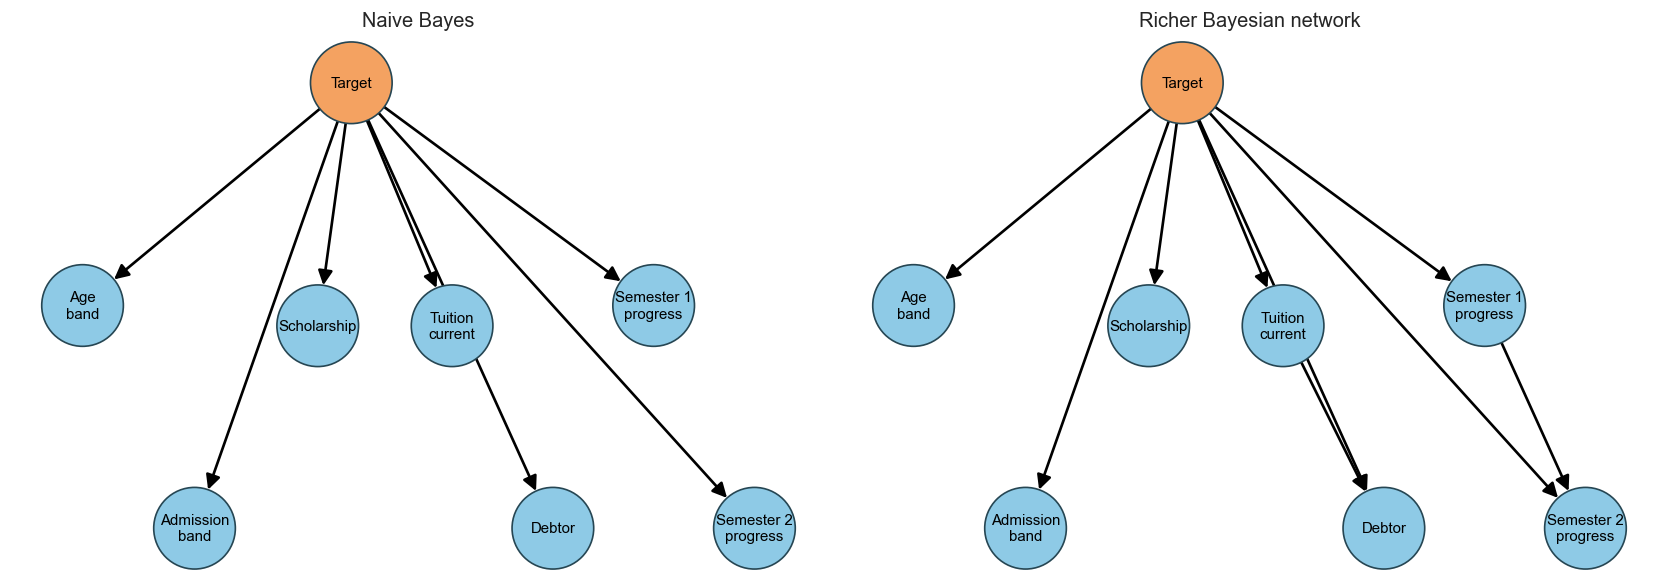

In [3]:
positions = {
    "Target": (0.0, 1.2),
    "Age band": (-2.4, 0.1),
    "Admission band": (-1.4, -1.0),
    "Scholarship": (-0.3, 0.0),
    "Tuition current": (0.9, 0.0),
    "Debtor": (1.8, -1.0),
    "Semester 1 progress": (2.7, 0.1),
    "Semester 2 progress": (3.6, -1.0),
}
display_labels = {
    "Target": "Target",
    "Age band": "Age\nband",
    "Admission band": "Admission\nband",
    "Scholarship": "Scholarship",
    "Tuition current": "Tuition\ncurrent",
    "Debtor": "Debtor",
    "Semester 1 progress": "Semester 1\nprogress",
    "Semester 2 progress": "Semester 2\nprogress",
}
nodes = list(positions)

naive_edges = [("Target", node) for node in nodes if node != "Target"]
rich_edges = naive_edges + [
    ("Tuition current", "Debtor"),
    ("Semester 1 progress", "Semester 2 progress"),
]

def draw_graph(ax, edges, title):
    graph = nx.DiGraph()
    graph.add_nodes_from(nodes)
    graph.add_edges_from(edges)
    node_colors = ["#f4a261" if node == "Target" else "#8ecae6" for node in graph.nodes]
    nx.draw_networkx(
        graph,
        pos=positions,
        labels=display_labels,
        node_color=node_colors,
        node_size=2400,
        edgecolors="#264653",
        arrows=True,
        arrowsize=18,
        width=1.6,
        font_size=9,
        ax=ax,
    )
    ax.set_title(title)
    ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
draw_graph(axes[0], naive_edges, "Naive Bayes")
draw_graph(axes[1], rich_edges, "Richer Bayesian network")
plt.tight_layout()
plt.show()

## Which Conditional-Independence Claims Look Reasonable?

Lecture 14 framed d-separation as a way to read independence statements from a graph. We can do a simple data check here, using only the **training split** so that the later holdout evaluation stays clean.

- `Age band` and `Debtor` should be close to conditionally independent once `Target` is known. That is the fork pattern `Age band <- Target -> Debtor`.
- `Tuition current` and `Debtor` should **not** be conditionally independent given `Target`, so the richer graph keeps an explicit edge.
- `Semester 1 progress` and `Semester 2 progress` should also remain dependent given `Target`, which motivates the second extra edge.

In [4]:
def conditional_chi_square(frame, left, right, given="Target"):
    rows = []
    for condition_value in ["Dropout", "Graduate"]:
        subset = frame[frame[given] == condition_value]
        contingency = pd.crosstab(subset[left], subset[right])
        _, p_value, _, _ = chi2_contingency(contingency)
        rows.append(
            {
                "Pair": f"{left} vs {right}",
                given: condition_value,
                "p-value": p_value,
            }
        )
    return rows

test_rows = []
test_rows.extend(conditional_chi_square(train_df, "Age band", "Debtor"))
test_rows.extend(conditional_chi_square(train_df, "Tuition current", "Debtor"))
test_rows.extend(conditional_chi_square(train_df, "Semester 1 progress", "Semester 2 progress"))

test_df = pd.DataFrame(test_rows)
formatted_test_df = test_df.copy()
formatted_test_df["p-value"] = formatted_test_df["p-value"].map(lambda value: f"{value:.3e}")
display(formatted_test_df)

tuition_debtor = []
sem_progress = []
for target_value in ["Dropout", "Graduate"]:
    tuition_table = pd.crosstab(
        train_df.loc[train_df["Target"] == target_value, "Tuition current"],
        train_df.loc[train_df["Target"] == target_value, "Debtor"],
        normalize="index",
    ).round(3)
    tuition_table.index = pd.MultiIndex.from_product(
        [[target_value], tuition_table.index],
        names=["Target", "Tuition current"],
    )
    tuition_debtor.append(tuition_table)

    progress_table = pd.crosstab(
        train_df.loc[train_df["Target"] == target_value, "Semester 1 progress"],
        train_df.loc[train_df["Target"] == target_value, "Semester 2 progress"],
        normalize="index",
    ).round(3)
    progress_table.index = pd.MultiIndex.from_product(
        [[target_value], progress_table.index],
        names=["Target", "Semester 1 progress"],
    )
    sem_progress.append(progress_table)

print("Conditional distribution of Debtor given Tuition current and Target (training split)")
display(pd.concat(tuition_debtor))

print("Conditional distribution of Semester 2 progress given Semester 1 progress and Target (training split)")
display(pd.concat(sem_progress))

,Pair,Target,p-value
0,Age band vs Debtor,Dropout,3.589e-01
1,Age band vs Debtor,Graduate,4.194e-01
2,Tuition current vs Debtor,Dropout,7.609e-42
3,Tuition current vs Debtor,Graduate,7.516e-11
4,Semester 1 progress vs Semester 2 progress,Dropout,1.691e-104
5,Semester 1 progress vs Semester 2 progress,Graduate,4.160e-99


Conditional distribution of Debtor given Tuition current and Target (training split)


Debtor                       No    Yes
Target   Tuition current              
Dropout  No               0.526  0.474
         Yes              0.898  0.102
Graduate No               0.667  0.333
         Yes              0.961  0.039

Conditional distribution of Semester 2 progress given Semester 1 progress and Target (training split)


Semester 2 progress           Strong   Weak
Target   Semester 1 progress               
Dropout  Strong                0.629  0.371
         Weak                  0.033  0.967
Graduate Strong                0.941  0.059
         Weak                  0.413  0.587

The p-values and conditional tables tell a consistent story:

- `Age band` and `Debtor` do not show strong residual association once `Target` is fixed.
- `Tuition current` and `Debtor` stay tightly linked inside both classes.
- `Semester 1 progress` and `Semester 2 progress` are even more strongly linked.

That is exactly the kind of evidence Lecture 14 had in mind: Naive Bayes is a perfectly valid Bayesian network, but sometimes the graph is too sparse to match the data.

In [5]:
print(f"Training rows: {len(train_df)}")
print(f"Holdout rows: {len(holdout_df)}")

Training rows: 2722
Holdout rows: 908


In [6]:
class DiscreteBayesNetClassifier:
    def __init__(self, class_var, parent_map, alpha=1.0):
        self.class_var = class_var
        self.parent_map = parent_map
        self.alpha = alpha

    def fit(self, frame):
        self.levels = {
            column: sorted(frame[column].astype(str).unique().tolist())
            for column in frame.columns
        }
        self.class_levels = self.levels[self.class_var]

        total_rows = len(frame)
        num_classes = len(self.class_levels)
        class_counts = frame[self.class_var].value_counts().to_dict()
        self.class_prior = {
            label: (class_counts.get(label, 0) + self.alpha)
            / (total_rows + self.alpha * num_classes)
            for label in self.class_levels
        }

        self.tables = {}
        for variable, parents in self.parent_map.items():
            variable_levels = self.levels[variable]
            grouped = frame.groupby(parents + [variable]).size() if parents else None
            parent_counts = frame.groupby(parents).size() if parents else None
            parent_spaces = itertools.product(*[self.levels[parent] for parent in parents]) if parents else [()]

            table = {}
            for parent_values in parent_spaces:
                denominator_key = parent_values if len(parent_values) != 1 else parent_values[0]
                denominator = (
                    parent_counts.get(denominator_key, 0) if parents else total_rows
                ) + self.alpha * len(variable_levels)

                probabilities = {}
                for value in variable_levels:
                    count_key = parent_values + (value,)
                    count_key = count_key if len(count_key) != 1 else count_key[0]
                    count = grouped.get(count_key, 0) if parents else int((frame[variable] == value).sum())
                    probabilities[value] = (count + self.alpha) / denominator
                table[parent_values] = probabilities

            self.tables[variable] = table
        return self

    def predict_proba(self, features):
        rows = []
        for _, row in features.iterrows():
            log_scores = {}
            for label in self.class_levels:
                log_probability = math.log(self.class_prior[label])
                for variable, parents in self.parent_map.items():
                    parent_values = tuple(
                        label if parent == self.class_var else row[parent]
                        for parent in parents
                    )
                    log_probability += math.log(
                        self.tables[variable][parent_values][row[variable]]
                    )
                log_scores[label] = log_probability

            max_log = max(log_scores.values())
            unnormalized = {
                label: math.exp(score - max_log)
                for label, score in log_scores.items()
            }
            total = sum(unnormalized.values())
            rows.append({label: unnormalized[label] / total for label in self.class_levels})

        return pd.DataFrame(rows)

    def predict(self, features):
        return self.predict_proba(features).idxmax(axis=1)

    def factorization(self):
        factors = [f"P({self.class_var})"]
        for variable, parents in self.parent_map.items():
            if parents:
                factors.append(f"P({variable} | {', '.join(parents)})")
            else:
                factors.append(f"P({variable})")
        return " * ".join(factors)

    def parameter_count(self):
        total = len(self.class_levels) - 1
        for variable, parents in self.parent_map.items():
            parent_configurations = math.prod(len(self.levels[parent]) for parent in parents) if parents else 1
            total += parent_configurations * (len(self.levels[variable]) - 1)
        return total

    def cpt(self, variable):
        parents = self.parent_map[variable]
        rows = []
        for parent_values, probabilities in self.tables[variable].items():
            row = {parent: value for parent, value in zip(parents, parent_values)}
            row.update(probabilities)
            rows.append(row)
        return pd.DataFrame(rows)

In [7]:
naive_parent_map = {
    "Age band": ["Target"],
    "Admission band": ["Target"],
    "Scholarship": ["Target"],
    "Tuition current": ["Target"],
    "Debtor": ["Target"],
    "Semester 1 progress": ["Target"],
    "Semester 2 progress": ["Target"],
}

rich_parent_map = {
    "Age band": ["Target"],
    "Admission band": ["Target"],
    "Scholarship": ["Target"],
    "Tuition current": ["Target"],
    "Debtor": ["Target", "Tuition current"],
    "Semester 1 progress": ["Target"],
    "Semester 2 progress": ["Target", "Semester 1 progress"],
}

naive_model = DiscreteBayesNetClassifier("Target", naive_parent_map, alpha=1.0).fit(train_df)
rich_model = DiscreteBayesNetClassifier("Target", rich_parent_map, alpha=1.0).fit(train_df)

factorization_df = pd.DataFrame(
    {
        "Factorization": [naive_model.factorization(), rich_model.factorization()],
        "Free parameters": [naive_model.parameter_count(), rich_model.parameter_count()],
    },
    index=["Naive Bayes", "Richer BN"],
)
display(factorization_df)

,Factorization,Free parameters
Naive Bayes,P(Target) * P(Age band | Target) * P(Admission band | Target) * P(Scholarship | Target) * P(Tuition current | Target) * P(Debtor | Target) * P(Semester 1 progress | Target) * P(Semester 2 progress | Target),19
Richer BN,"P(Target) * P(Age band | Target) * P(Admission band | Target) * P(Scholarship | Target) * P(Tuition current | Target) * P(Debtor | Target, Tuition current) * P(Semester 1 progress | Target) * P(Semester 2 progress | Target, Semester 1 progress)",23


The richer network only adds **four** extra free parameters here, but it removes two conditional-independence assumptions that the data clearly reject.

,Accuracy,Log loss
Model,,
Naive Bayes,0.892,0.344
Richer BN,0.890,0.305


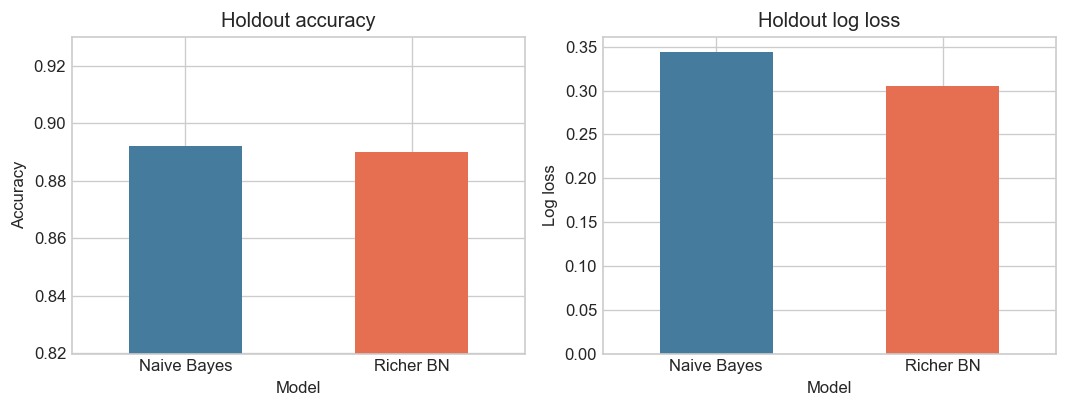

In [8]:
X_holdout = holdout_df.drop(columns=["Target"])
y_holdout = holdout_df["Target"].reset_index(drop=True)

evaluation_rows = []
probability_cache = {}
for name, model in {
    "Naive Bayes": naive_model,
    "Richer BN": rich_model,
}.items():
    probabilities = model.predict_proba(X_holdout)
    predictions = probabilities.idxmax(axis=1)
    probability_cache[name] = probabilities
    evaluation_rows.append(
        {
            "Model": name,
            "Accuracy": accuracy_score(y_holdout, predictions),
            "Log loss": log_loss(
                y_holdout,
                probabilities[["Dropout", "Graduate"]],
                labels=["Dropout", "Graduate"],
            ),
        }
    )

evaluation_df = pd.DataFrame(evaluation_rows).set_index("Model").round(3)
display(evaluation_df)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
evaluation_df["Accuracy"].plot(kind="bar", ax=axes[0], color=["#457b9d", "#e76f51"], rot=0)
evaluation_df["Log loss"].plot(kind="bar", ax=axes[1], color=["#457b9d", "#e76f51"], rot=0)
axes[0].set_ylim(0.82, 0.93)
axes[0].set_title("Holdout accuracy")
axes[0].set_ylabel("Accuracy")
axes[1].set_title("Holdout log loss")
axes[1].set_ylabel("Log loss")
plt.tight_layout()
plt.show()

Accuracy stays about the same, but the richer BN improves **log loss**. That is a useful graphical-model lesson: a better dependency structure can improve the quality of the posterior probabilities even when the hard classification decisions barely move.

In [9]:
graduate_not_current = train_df[
    (train_df["Target"] == "Graduate")
    & (train_df["Tuition current"] == "No")
]
manual_count = int((graduate_not_current["Debtor"] == "Yes").sum())
total_count = len(graduate_not_current)
num_debtor_states = train_df["Debtor"].nunique()
manual_probability = (manual_count + 1) / (total_count + num_debtor_states)

print("Manual CPT estimate with Laplace smoothing")
print(
    "P(Debtor = Yes | Target = Graduate, Tuition current = No) = "
    f"({manual_count} + 1) / ({total_count} + {num_debtor_states}) = {manual_probability:.3f}"
)
print()
print("Learned CPT for Debtor in the richer BN")
display(rich_model.cpt("Debtor").round(3))
print("Learned CPT for Semester 2 progress in the richer BN")
display(rich_model.cpt("Semester 2 progress").round(3))

Manual CPT estimate with Laplace smoothing
P(Debtor = Yes | Target = Graduate, Tuition current = No) = (8 + 1) / (24 + 2) = 0.346

Learned CPT for Debtor in the richer BN


,Target,Tuition current,No,Yes
0,Dropout,No,0.526,0.474
1,Dropout,Yes,0.896,0.104
2,Graduate,No,0.654,0.346
3,Graduate,Yes,0.960,0.040


Learned CPT for Semester 2 progress in the richer BN


,Target,Semester 1 progress,Strong,Weak
0,Dropout,Strong,0.628,0.372
1,Dropout,Weak,0.035,0.965
2,Graduate,Strong,0.940,0.060
3,Graduate,Weak,0.414,0.586


## Takeaways

- Naive Bayes is already a Bayesian network, but its star-shaped graph encodes strong conditional-independence assumptions.
- On this student-success dataset, two of those assumptions are visibly too strong: financial status variables remain linked, and first-semester progress remains linked to second-semester progress.
- With a fixed graph, learning is straightforward: estimate each CPT by counting the relevant parent/child configurations and apply Laplace smoothing.
- Even a tiny graph change can improve the quality of posterior probabilities without requiring a much larger parameter budget.